In [1]:
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
import pandas as pd
# load data
aisles = pd.read_csv('archive (3)/aisles.csv')
departments = pd.read_csv('archive (3)/departments.csv')
order_products_prior = pd.read_csv('archive (3)/order_products__prior.csv')
order_products_train = pd.read_csv('archive (3)/order_products__train.csv')
orders = pd.read_csv('archive (3)/orders.csv')
products = pd.read_csv('archive (3)/products.csv')

In [3]:
#Hiển thị top các sản phẩm được mua nhiều nhất:

#Join order_products_prior với products
merge_product=order_products_prior.merge(products,on='product_id',how='left')
#Group theo product để đếm số lượng đơn đặt
product_counts = merge_product.groupby('product_name').size().reset_index(name='order_count')
# sort giảm dần theo số lượng:
product_counts=product_counts.sort_values('order_count',ascending=False)
# lấy top 10 sản phẩm được mua nhiều nhất
top10_products=product_counts.head(10)


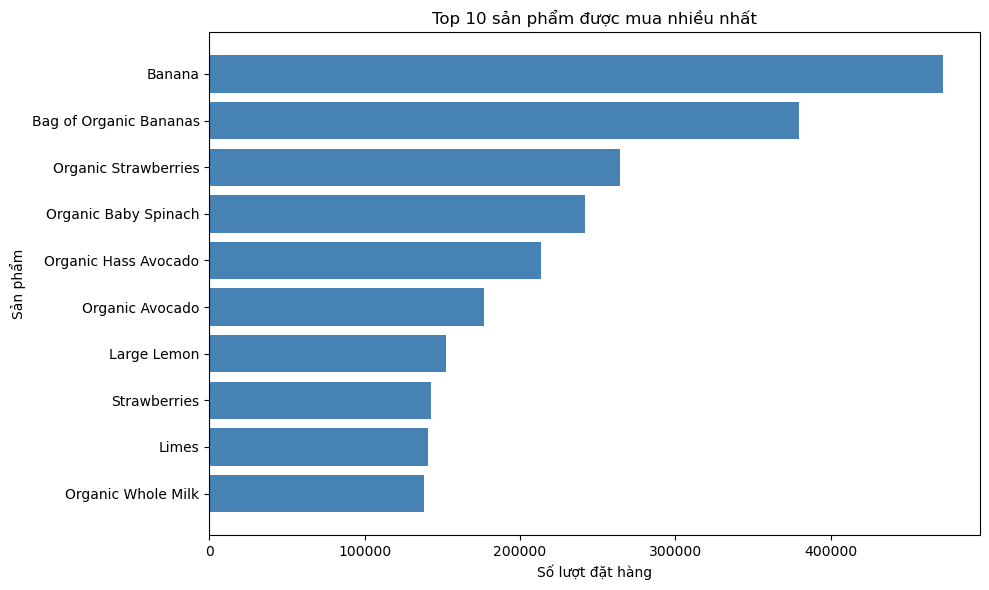

In [4]:
#Vẽ barh:
plt.figure(figsize=(10, 6))
plt.barh(top10_products['product_name'], top10_products['order_count'], color='steelblue')
plt.xlabel('Số lượt đặt hàng')
plt.ylabel('Sản phẩm')
plt.title('Top 10 sản phẩm được mua nhiều nhất')
plt.gca().invert_yaxis()   
plt.tight_layout()
plt.show()

In [5]:
# Boxplot để thể hiện phần lớn số lượng đơn mà các user đặt nằm ở khoảng nào

#join bảng order với order_products_prior
merge_order= order_products_prior.merge(orders,on='order_id',how='right')
# group theo user_id để tính số lượng đơn hàng
order_counts= merge_order.groupby('user_id').size().reset_index(name = 'user_order_counts')


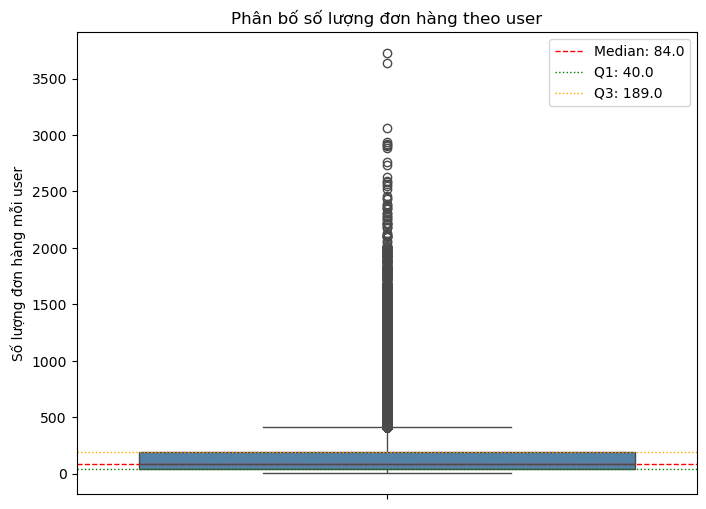

In [12]:
Q1 = order_counts['user_order_counts'].quantile(0.25)
median = order_counts['user_order_counts'].median()
Q3 = order_counts['user_order_counts'].quantile(0.75)

plt.figure(figsize=(8, 6))
sns.boxplot(y=order_counts['user_order_counts'], color='steelblue')

# Vẽ thêm đường ngang tham chiếu tại các mốc quan trọng
plt.axhline(median, color='red', linestyle='--', linewidth=1, label=f'Median: {median}')
plt.axhline(Q1, color='green', linestyle=':', linewidth=1, label=f'Q1: {Q1}')
plt.axhline(Q3, color='orange', linestyle=':', linewidth=1, label=f'Q3: {Q3}')


plt.legend()
plt.ylabel('Số lượng đơn hàng mỗi user')
plt.title('Phân bố số lượng đơn hàng theo user')
plt.show()

In [ ]:
top_user_id= order_counts.sort_values('user_order_counts',ascending=False)


In [20]:
#top 10 khách hàng mua nhiều nhất
top_10_users=top_user_id.head(10)
top_10_users=top_10_users.reset_index(drop=True)
top_10_users

,user_id,user_order_counts
0,201268,3726
1,129928,3639
2,164055,3062
3,186704,2937
4,176478,2922
5,182401,2908
6,137629,2902
7,33731,2889
8,108187,2761
9,4694,2736
